# Media Mix Modeling (MMM) Without Transformations

This notebook demonstrates how to build a Marketing Mix Model **without adstock or saturation transformations**. This simpler model assumes:
- Immediate impact of media spend (no carry-over effects)
- Linear relationship between spend and sales (no diminishing returns)

## Prepare Notebook

Let's import the necessary libraries:

In [1]:
import sys
sys.path.insert(0, ".")

import yaml
from pymc_marketing.mmm.mmm import MMM

# Load configuration from YAML file
with open("mmm_config.yml", "r") as f:
    config = yaml.safe_load(f)

print("Configuration loaded successfully!")
print(f"Data source: {config['data']['source']}")
print(f"Channel columns: {config['data']['columns']['channel_columns']}")
print(f"MCMC chains: {config['sampling']['mcmc']['chains']}")

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


Configuration loaded successfully!
Data source: https://raw.githubusercontent.com/pymc-labs/pymc-marketing/main/data/mmm_example.csv
Channel columns: ['x1', 'x2']
MCMC chains: 4


## Configure Logging

Set up logging to track the modeling process:

In [2]:
import logging

# Get logging configuration from config
log_config = config['logging']

# Prevent duplicate logs by clearing existing root handlers first
root_logger = logging.getLogger()
if root_logger.hasHandlers():
    root_logger.handlers.clear()

# Apply base configuration to ROOT only
logging.basicConfig(
    level=getattr(logging, log_config['level']),
    format=log_config['format'],
    datefmt=log_config['date_format']
)

# Configure pymc_marketing loggers
for name in list(logging.root.manager.loggerDict.keys()):
    if name.startswith("pymc_marketing"):
        pkg_logger = logging.getLogger(name)
        for h in list(pkg_logger.handlers):
            pkg_logger.removeHandler(h)
        pkg_logger.propagate = True
        pkg_logger.setLevel(getattr(logging, log_config['mmm_logger']['level']))

# Configure the main MMM logger
mmm_logger = logging.getLogger(log_config['mmm_logger']['name'])
mmm_logger.setLevel(getattr(logging, log_config['mmm_logger']['level']))
for h in list(mmm_logger.handlers):
    mmm_logger.removeHandler(h)
mmm_logger.propagate = True

print("Logging configured successfully!")

Logging configured successfully!


## Import Libraries

In [3]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pymc_extras.prior import Prior
from pymc_marketing.mmm.components.adstock import NoAdstock
from pymc_marketing.mmm.components.saturation import NoSaturation

# Apply visualization configuration
viz_config = config['visualization']
az.style.use(viz_config['style'])
plt.rcParams["figure.figsize"] = viz_config['figure']['figsize']
plt.rcParams["figure.dpi"] = viz_config['figure']['dpi']

%config InlineBackend.figure_format = viz_config['backend']['format']

%load_ext autoreload
%autoreload 2

## Set Random Seed

In [4]:
# Set random seed for reproducibility
seed = config['sampling']['random_seed']
rng = np.random.default_rng(seed=seed)
print(f"Random seed set to: {seed}")

Random seed set to: 327


## Load Data

We'll use the same synthetic dataset that simulates weekly sales data along with spend on two marketing channels (x1 and x2), plus some control variables for special events.

In [5]:
# Load the data from config-specified source
data_config = config['data']
url = data_config['source']
data = pd.read_csv(url, parse_dates=[data_config['columns']['date_column']])

print(f"Data shape: {data.shape}")
data.head()

Data shape: (179, 8)


,date_week,y,x1,x2,event_1,event_2,dayofyear,t
0,2018-04-02,3984.662237,0.318580,0.0,0.0,0.0,92,0
1,2018-04-09,3762.871794,0.112388,0.0,0.0,0.0,99,1
2,2018-04-16,4466.967388,0.292400,0.0,0.0,0.0,106,2
3,2018-04-23,3864.219373,0.071399,0.0,0.0,0.0,113,3
4,2018-04-30,4441.625278,0.386745,0.0,0.0,0.0,120,4


## Visualize Data

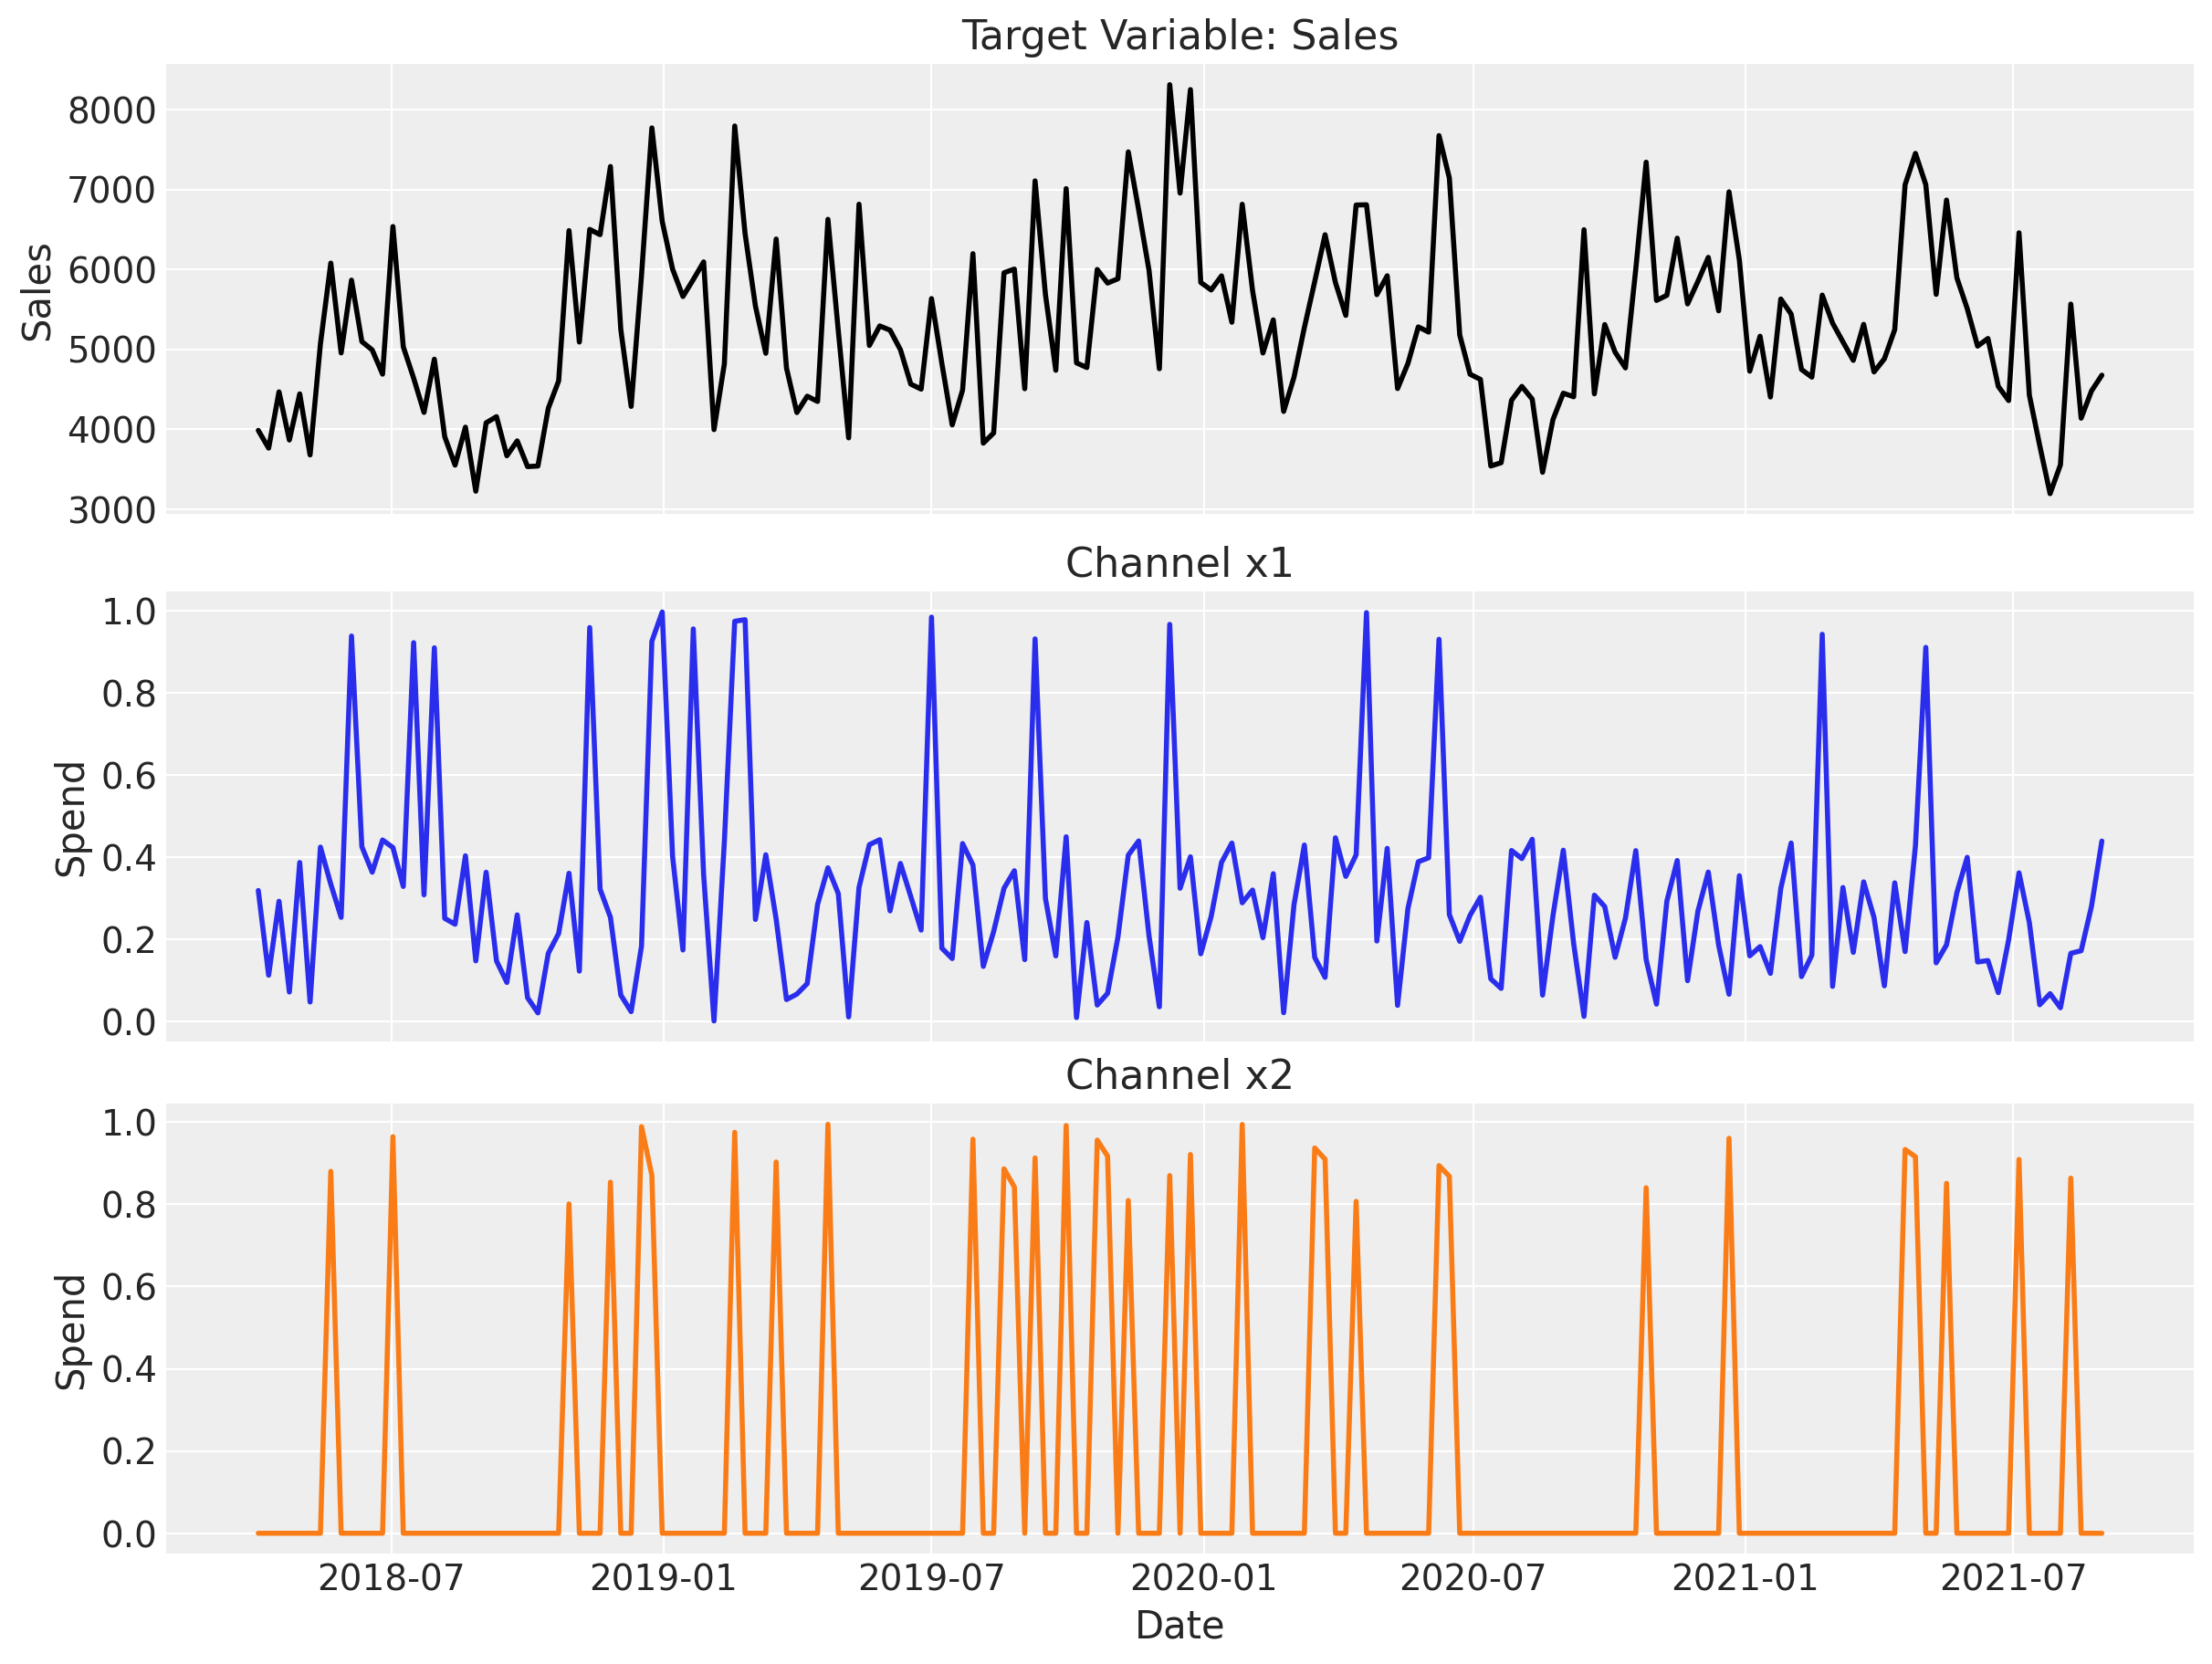

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

# Get column names from config
date_col = config['data']['columns']['date_column']
target_col = config['data']['columns']['target_column']
channel_cols = config['data']['columns']['channel_columns']

# Sales
axes[0].plot(data[date_col], data[target_col], color="black", linewidth=2)
axes[0].set(ylabel="Sales", title="Target Variable: Sales")

# Channel 1
axes[1].plot(data[date_col], data[channel_cols[0]], color="C0", linewidth=2)
axes[1].set(ylabel="Spend", title=f"Channel {channel_cols[0]}")

# Channel 2
axes[2].plot(data[date_col], data[channel_cols[1]], color="C1", linewidth=2)
axes[2].set(xlabel="Date", ylabel="Spend", title=f"Channel {channel_cols[1]}");

## Feature Engineering

For our MMM model, we'll include:

- **Trend**: A linear trend to capture long-term growth
- **Seasonality**: Yearly seasonality (handled automatically by the model)
- **Events**: Binary indicators for special events
- **Media channels**: Our two advertising channels (with **NO transformations**)

In [7]:
# Add a simple linear trend feature
data["t"] = range(len(data))

# Split into features (X) and target (y) using config
target_col = config['data']['columns']['target_column']
X = data.drop(target_col, axis=1)
y = data[target_col]

print(f"Features: {X.columns.tolist()}")

Features: ['date_week', 'x1', 'x2', 'event_1', 'event_2', 'dayofyear', 't']


## Model Specification (Without Transformations)

The key difference in this notebook is that we use **NoAdstock** and **NoSaturation** transformations:

- **NoAdstock**: No carry-over effects from past media spend (immediate impact only)
- **NoSaturation**: Linear relationship between spend and sales (no diminishing returns)

This is achieved by using:
- `adstock=NoAdstock()` - No adstock transformation (l_max defaults to 1)
- `saturation=NoSaturation()` - Linear saturation (no diminishing returns)

### Setting Priors

In [8]:
# Calculate spend share for each channel
channel_cols = config['data']['columns']['channel_columns']
total_spend_per_channel = data[channel_cols].sum(axis=0)
spend_share = total_spend_per_channel / total_spend_per_channel.sum()

print("Spend share per channel:")
print(spend_share)

# Use spend share to inform prior on channel contributions
if config['priors']['use_spend_share_priors']:
    n_channels = config['priors']['spend_share_multiplier']
    prior_sigma = n_channels * spend_share.to_numpy()
    print(f"\nPrior sigma for channels: {prior_sigma}")
else:
    prior_sigma = None
    print("\nUsing default priors (not spend-share informed)")

Spend share per channel:
x1    0.65632
x2    0.34368
dtype: float64

Prior sigma for channels: [1.31263903 0.68736097]


### Define Model Configuration

In [9]:
# Build model configuration from config file
prior_config = config['priors']

# Build the model_config dictionary
my_model_config = {
    "intercept": Prior(
        prior_config['intercept']['distribution'],
        mu=prior_config['intercept']['mu'],
        sigma=prior_config['intercept']['sigma']
    ),
    "gamma_control": Prior(
        prior_config['gamma_control']['distribution'],
        mu=prior_config['gamma_control']['mu'],
        sigma=prior_config['gamma_control']['sigma']
    ),
    "gamma_fourier": Prior(
        prior_config['gamma_fourier']['distribution'],
        mu=prior_config['gamma_fourier']['mu'],
        b=prior_config['gamma_fourier']['b']
    ),
    "likelihood": Prior(
        prior_config['likelihood']['distribution'],
        sigma=Prior(
            prior_config['likelihood']['sigma']['distribution'],
            sigma=prior_config['likelihood']['sigma']['sigma']
        )
    ),
}

# Add beta prior for NoSaturation if using spend-share informed priors
if prior_sigma is not None:
    my_model_config["saturation_beta"] = Prior("HalfNormal", sigma=prior_sigma)

# Sampler configuration
my_sampler_config = {"progressbar": config['sampling']['progressbar']}

# Get model configuration
model_config = config['model']

# Initialize the MMM model WITHOUT transformations
# Use NoAdstock and NoSaturation - no parameters needed!
mmm = MMM(
    model_config=my_model_config,
    sampler_config=my_sampler_config,
    date_column=config['data']['columns']['date_column'],
    adstock=NoAdstock(),  # No adstock transformation (l_max defaults to 1)
    saturation=NoSaturation(),  # Linear saturation (no diminishing returns)
    channel_columns=config['data']['columns']['channel_columns'],
    control_columns=config['data']['columns']['control_columns'],
    yearly_seasonality=model_config['seasonality']['yearly_seasonality'],
)

print("\n" + "="*70)
print("MODEL INITIALIZED WITHOUT TRANSFORMATIONS")
print("Adstock: NoAdstock() - immediate impact, no carry-over")
print("Saturation: NoSaturation() - linear relationship, no diminishing returns")
print("="*70)

2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Initializing BaseMMM model
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - date_column: date_week
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - channel_columns: ['x1', 'x2']
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - adstock: NoAdstock
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - saturation: NoSaturation
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - time_varying_intercept: False
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - time_varying_media: False
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - control_columns: ['event_1', 'event_2', 't']
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - yearly_seasonality: 2
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - va


MODEL INITIALIZED WITHOUT TRANSFORMATIONS
Adstock: NoAdstock() - immediate impact, no carry-over
Saturation: NoSaturation() - linear relationship, no diminishing returns


## Prior Predictive Check

Before fitting, let's check that our priors are reasonable:

2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Starting prior predictive sampling
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - X shape: (179, 7)
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - y shape: (179,)
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - samples: 1000, extend_idata: True, combined: True
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Starting PyMC model building
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Model building input data shapes - X: (179, 7), y: (179,)
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Starting data preprocessing
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - Input data shapes - X: (179, 7), y: (179,)
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - X columns: ['date_week', 'x1', 'x2', 'event_1', 'event_2', 'dayofyear', 't']
2025-10-22 23:41:33 - pymc_marketing.mmm.mmm.MMM - INFO - X date ra

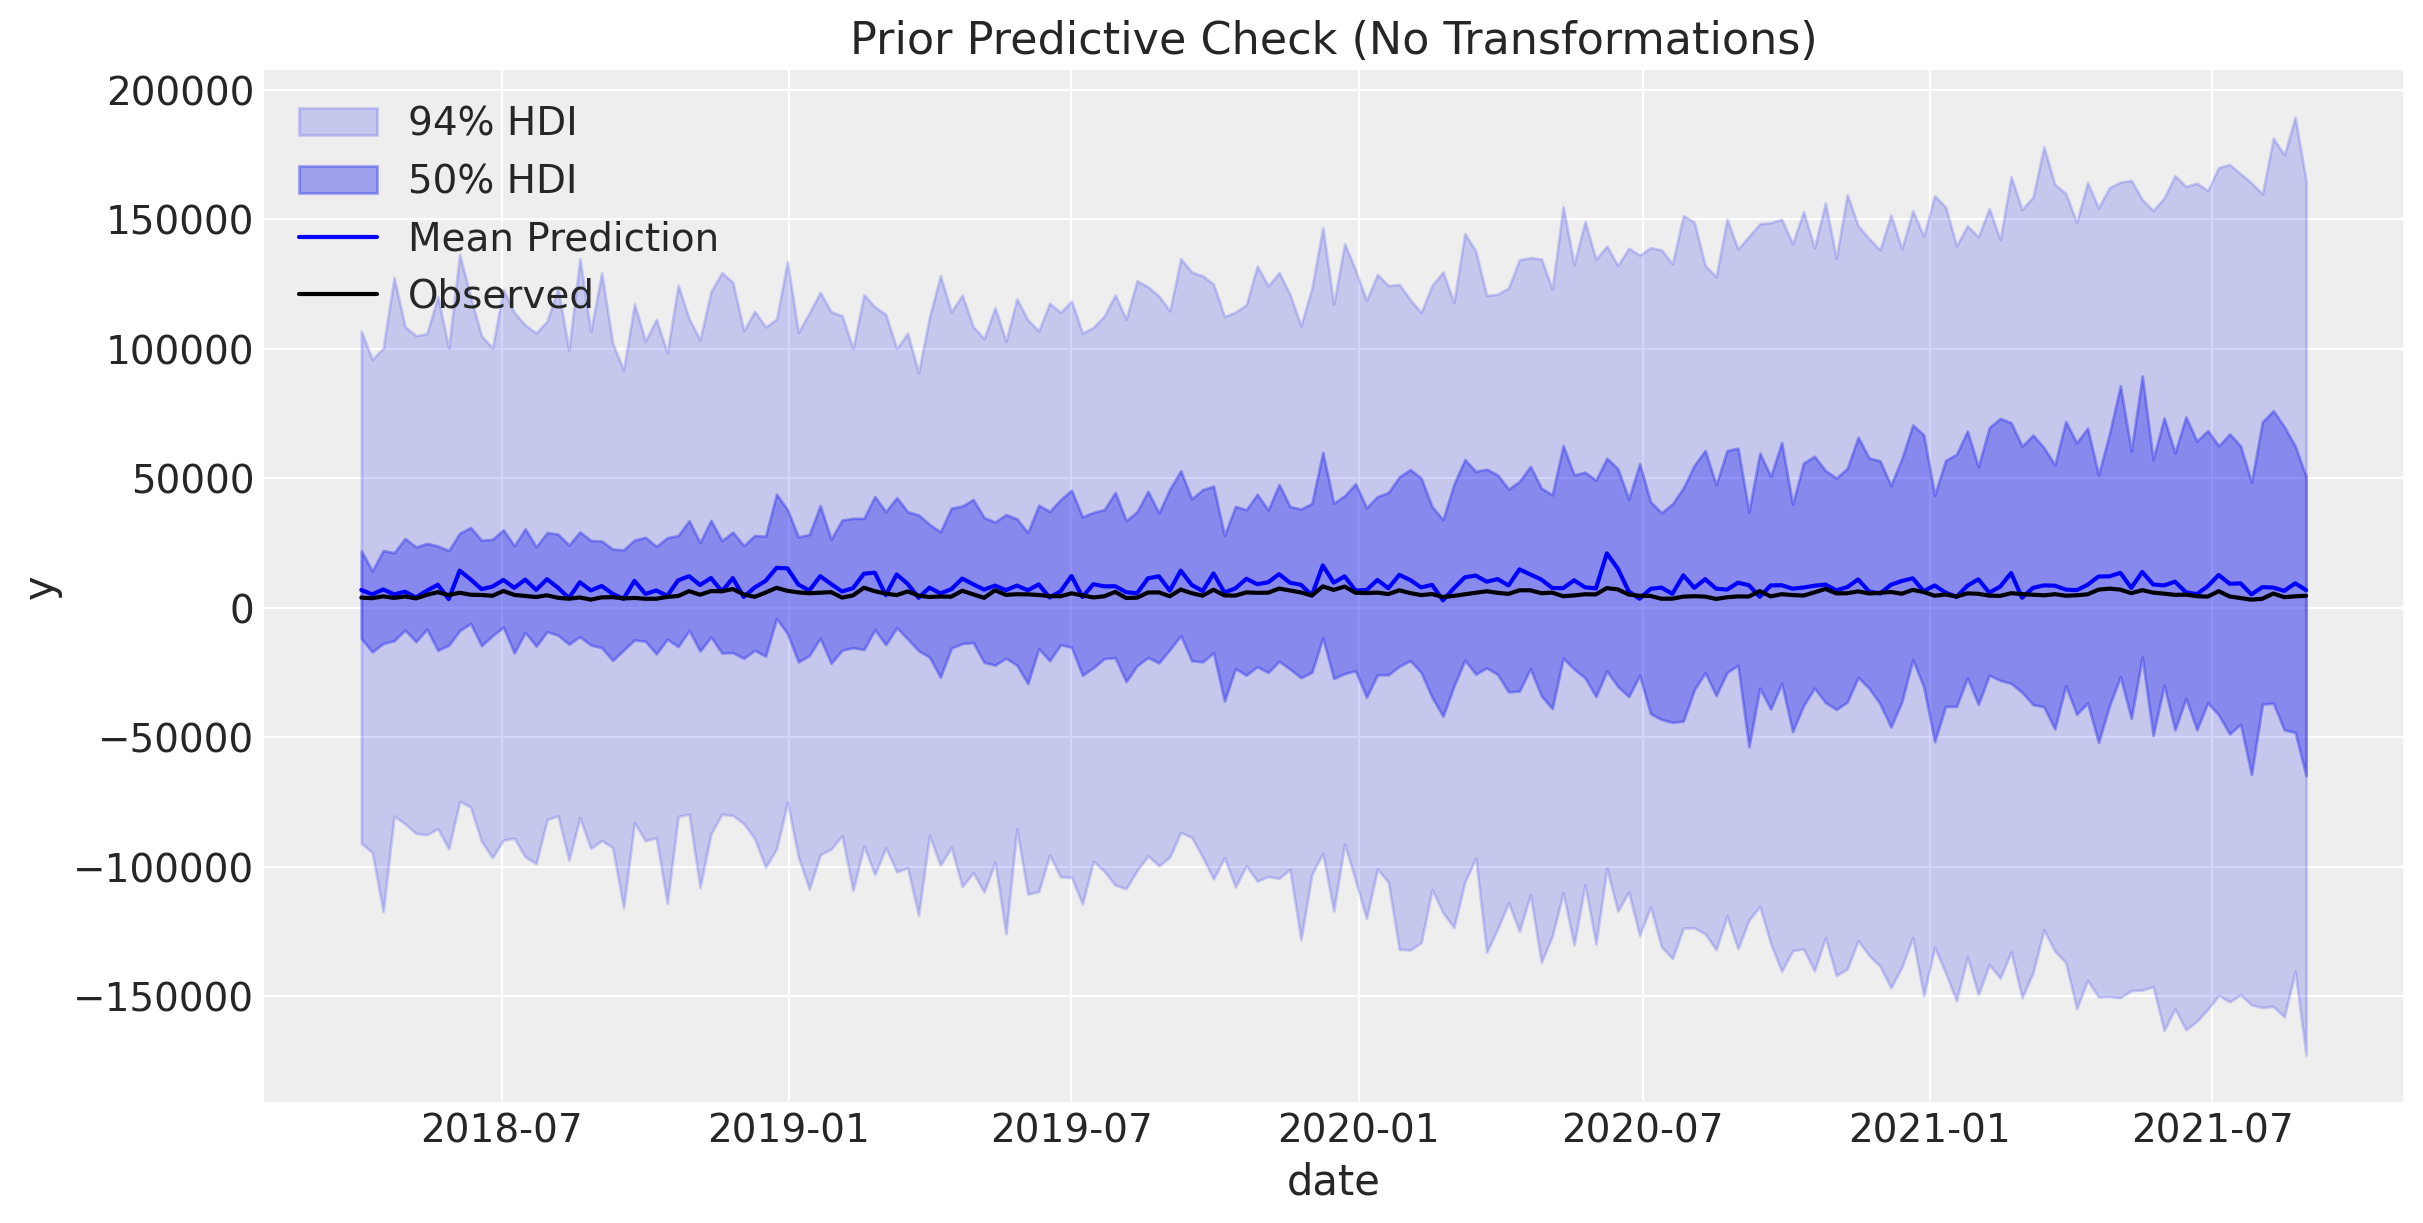

In [10]:
# Generate prior predictive samples using config
prior_samples = config['sampling']['prior_predictive']['samples']
mmm.sample_prior_predictive(X, y, samples=prior_samples, random_seed=rng)

# Plot prior predictive distribution
fig, ax = plt.subplots(figsize=(12, 6))
mmm.plot_prior_predictive(ax=ax, original_scale=True)
ax.legend(loc="upper left")
ax.set_title("Prior Predictive Check (No Transformations)");

## Model Fitting

Now let's fit the model to our data using MCMC sampling:

In [11]:
# Fit the model using MCMC configuration from config file
mcmc_config = config['sampling']['mcmc']

_ = mmm.fit(
    X=X,
    y=y,
    chains=mcmc_config['chains'],
    target_accept=mcmc_config['target_accept'],
    nuts_sampler=mcmc_config['nuts_sampler'],
    random_seed=rng,
)

2025-10-22 23:41:46 - pymc_marketing.mmm.mmm.MMM - INFO - Starting model fitting
2025-10-22 23:41:46 - pymc_marketing.mmm.mmm.MMM - INFO - Fit input data shapes - X: (179, 7), y: (179,)
2025-10-22 23:41:46 - pymc_marketing.mmm.mmm.MMM - INFO - Fit parameters - progressbar: None, random_seed: Generator(PCG64)
2025-10-22 23:41:46 - pymc_marketing.mmm.mmm.MMM - INFO - Additional kwargs: ['chains', 'target_accept', 'nuts_sampler']
c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:2025-10-22 23:41:47,391:jax._src.xla_bridge:822: Unable to initialize backend 'tpu': UNIMPLEMENTED: LoadPjrtPlugin is not implemented on windows yet.
2025-10-22 23:41:47 - jax._src.xla_bridge - INFO - Unable to initialize backend 'tpu': UNIMPLEMENTED: LoadPjrtPlugi

c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2025-10-22 23:42:43 - pymc_marketing.mmm.mmm.MMM - INFO - Model fitting completed successfully
2025-10-22 23:42:43 - pymc_marketing.mmm.mmm.MMM - INFO - Inference data groups: ['posterior', 'sample_stats', 'prior', 'prior_predictive', 'observed_data', 'constant_data', 'fit_data']
2025-10-22 23:42:43 - pymc_marketing.mmm.mmm.MMM - INFO - Posterior variables: ['intercept', 'gamma_control', 'gamma_fourier', 'saturation_beta', 'y_sigma', 'channel_contribution', 'total_contribution', 'control_contribution', 'fourier_contribution', 'yearly_seasonality_contribution', 'mu', 'channel_contribution_original_scale', 'total_contribution_original_scale', 'control_contribution_original_scale', 'yearly_seasonality_contribution_original_scale', 'y_original_scale']


## Model Diagnostics

After fitting, we should check the model quality:

In [12]:
# Check for divergences
n_divergences = mmm.idata["sample_stats"]["diverging"].sum().item()
print(f"Number of divergences: {n_divergences}")

if n_divergences == 0:
    print("✓ No divergences - sampling was successful!")
else:
    print("⚠ Warning: Model had divergences. Consider increasing target_accept.")

Number of divergences: 0
✓ No divergences - sampling was successful!


### Parameter Summary

In [13]:
mmm.fit_result

<xarray.Dataset> Size: 109MB
Dimensions:                                         (chain: 4, draw: 1000,
                                                     control: 3,
                                                     fourier_mode: 4,
                                                     channel: 2, date: 179)
Coordinates:
  * chain                                           (chain) int64 32B 0 1 2 3
  * draw                                            (draw) int64 8kB 0 1 ... 999
  * control                                         (control) <U7 84B 'event_...
  * fourier_mode                                    (fourier_mode) <U5 80B 's...
  * channel                                         (channel) <U2 16B 'x1' 'x2'
  * date                                            (date) datetime64[ns] 1kB ...
Data variables: (12/16)
    intercept                                       (chain, draw) float64 32kB ...
    gamma_control                                   (chain, draw, control) float64 96kB ...
    gamma_fourier                                   (chain, draw, fourier_mode) float64 128kB ...
    saturation_beta                                 (chain, draw, channel) float64 64kB ...
    y_sigma                                         (chain, draw) float64 32kB ...
    channel_contribution                            (chain, draw, date, channel) float64 11MB ...
    ...                                              ...
    mu                                              (chain, draw, date) float64 6MB ...
    channel_contribution_original_scale             (chain, draw, date, channel) float64 11MB ...
    total_contribution_original_scale               (chain, draw, date) float64 6MB ...
    control_contribution_original_scale             (chain, draw, date, control) float64 17MB ...
    yearly_seasonality_contribution_original_scale  (chain, draw, date) float64 6MB ...
    y_original_scale                                (chain, draw, date) float64 6MB ...
Attributes:
    created_at:                 2025-10-23T04:41:55.471762+00:00
    arviz_version:              0.22.0
    inference_library:          numpyro
    inference_library_version:  0.19.0
    sampling_time:              7.072747
    tuning_steps:               1000
    pymc_marketing_version:     0.16.0

### Trace Plots

Note: Since we're using NoSaturation (linear), we have `saturation_beta` (channel coefficients) but no `saturation_lam` or `adstock_alpha` parameters.

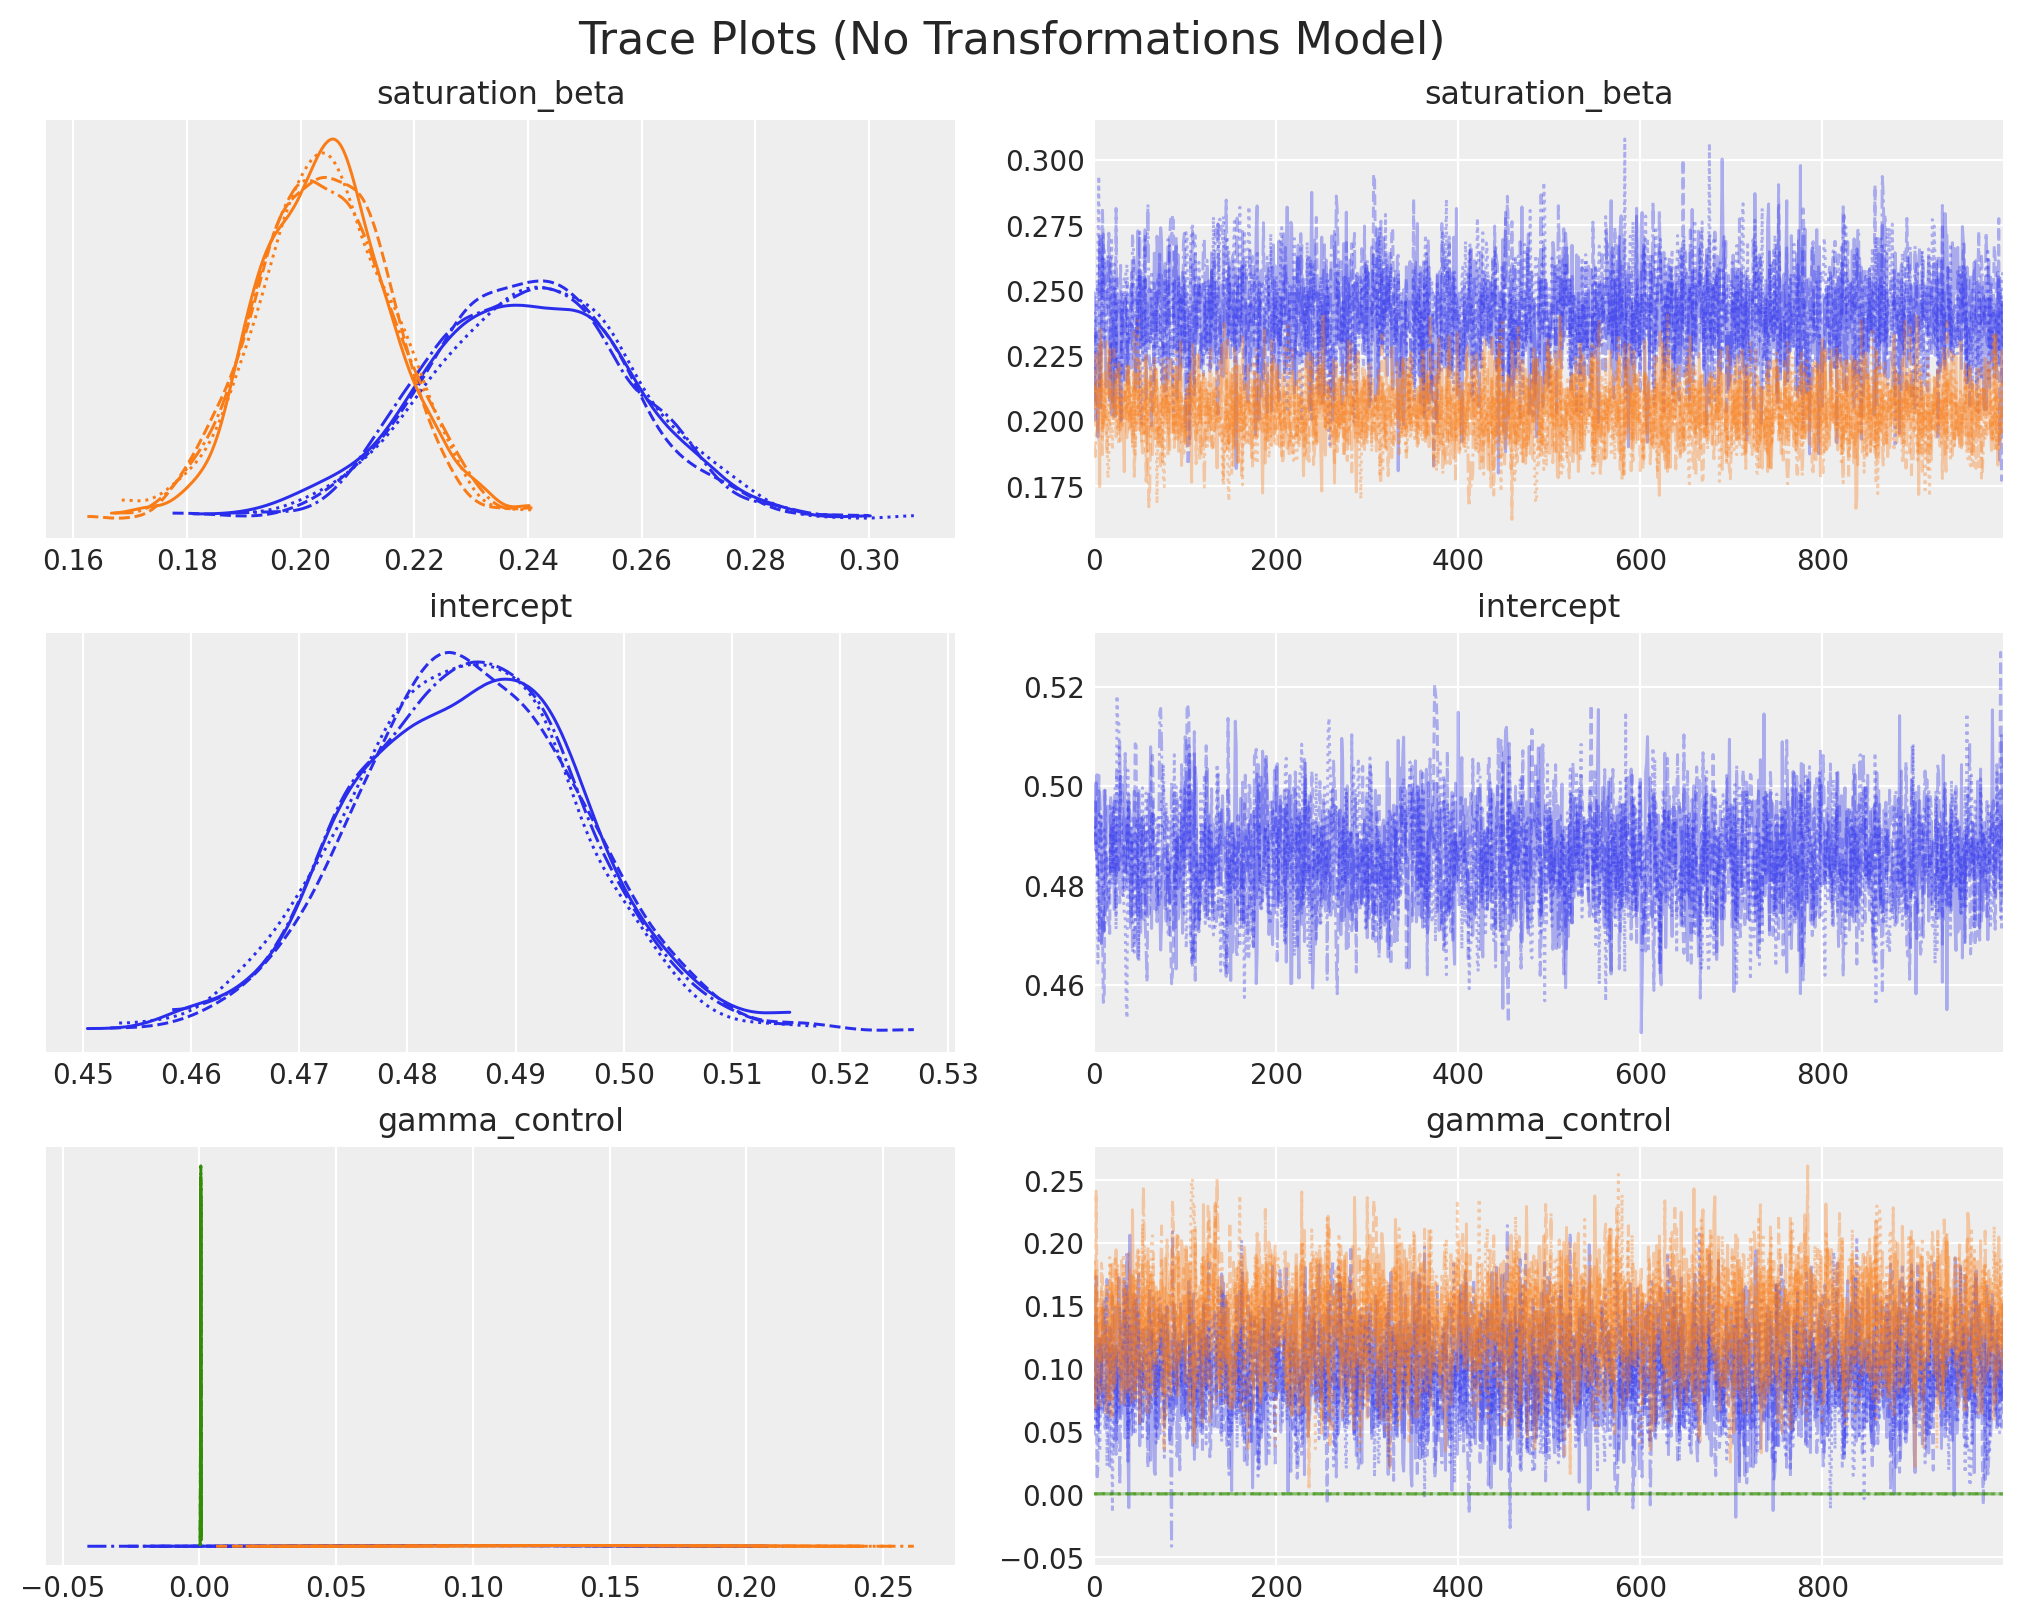

In [14]:
# Plot traces for key parameters
_ = az.plot_trace(
    data=mmm.fit_result,
    var_names=[
        "saturation_beta",  # Channel coefficients (linear, no saturation)
        "intercept",
        "gamma_control",
    ],
    compact=True,
    backend_kwargs={"figsize": (10, 8), "layout": "constrained"},
)
plt.gcf().suptitle("Trace Plots (No Transformations Model)", fontsize=16);

## Posterior Predictive Check

How well does our model fit the observed data?

2025-10-22 23:42:44 - pymc_marketing.mmm.mmm.MMM - INFO - Starting posterior predictive sampling
2025-10-22 23:42:44 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - X shape: (179, 7)
2025-10-22 23:42:44 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - extend_idata: True, combined: True
2025-10-22 23:42:44 - pymc_marketing.mmm.mmm.MMM - INFO - Input parameters - include_last_observations: False, original_scale: True
Sampling: [y]
2025-10-22 23:42:44 - pymc.sampling.forward - INFO - Sampling: [y]


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2025-10-22 23:42:45 - pymc_marketing.mmm.mmm.MMM - INFO - Posterior predictive sampling completed successfully
2025-10-22 23:42:45 - pymc_marketing.mmm.mmm.MMM - INFO - Output samples shape: Frozen({'date': 179, 'sample': 4000})
2025-10-22 23:42:45 - pymc_marketing.mmm.mmm.MMM - INFO - Output variables: ['y']
2025-10-22 23:42:45 - pymc_marketing.mmm.mmm.MMM - INFO - Samples returned in original scale


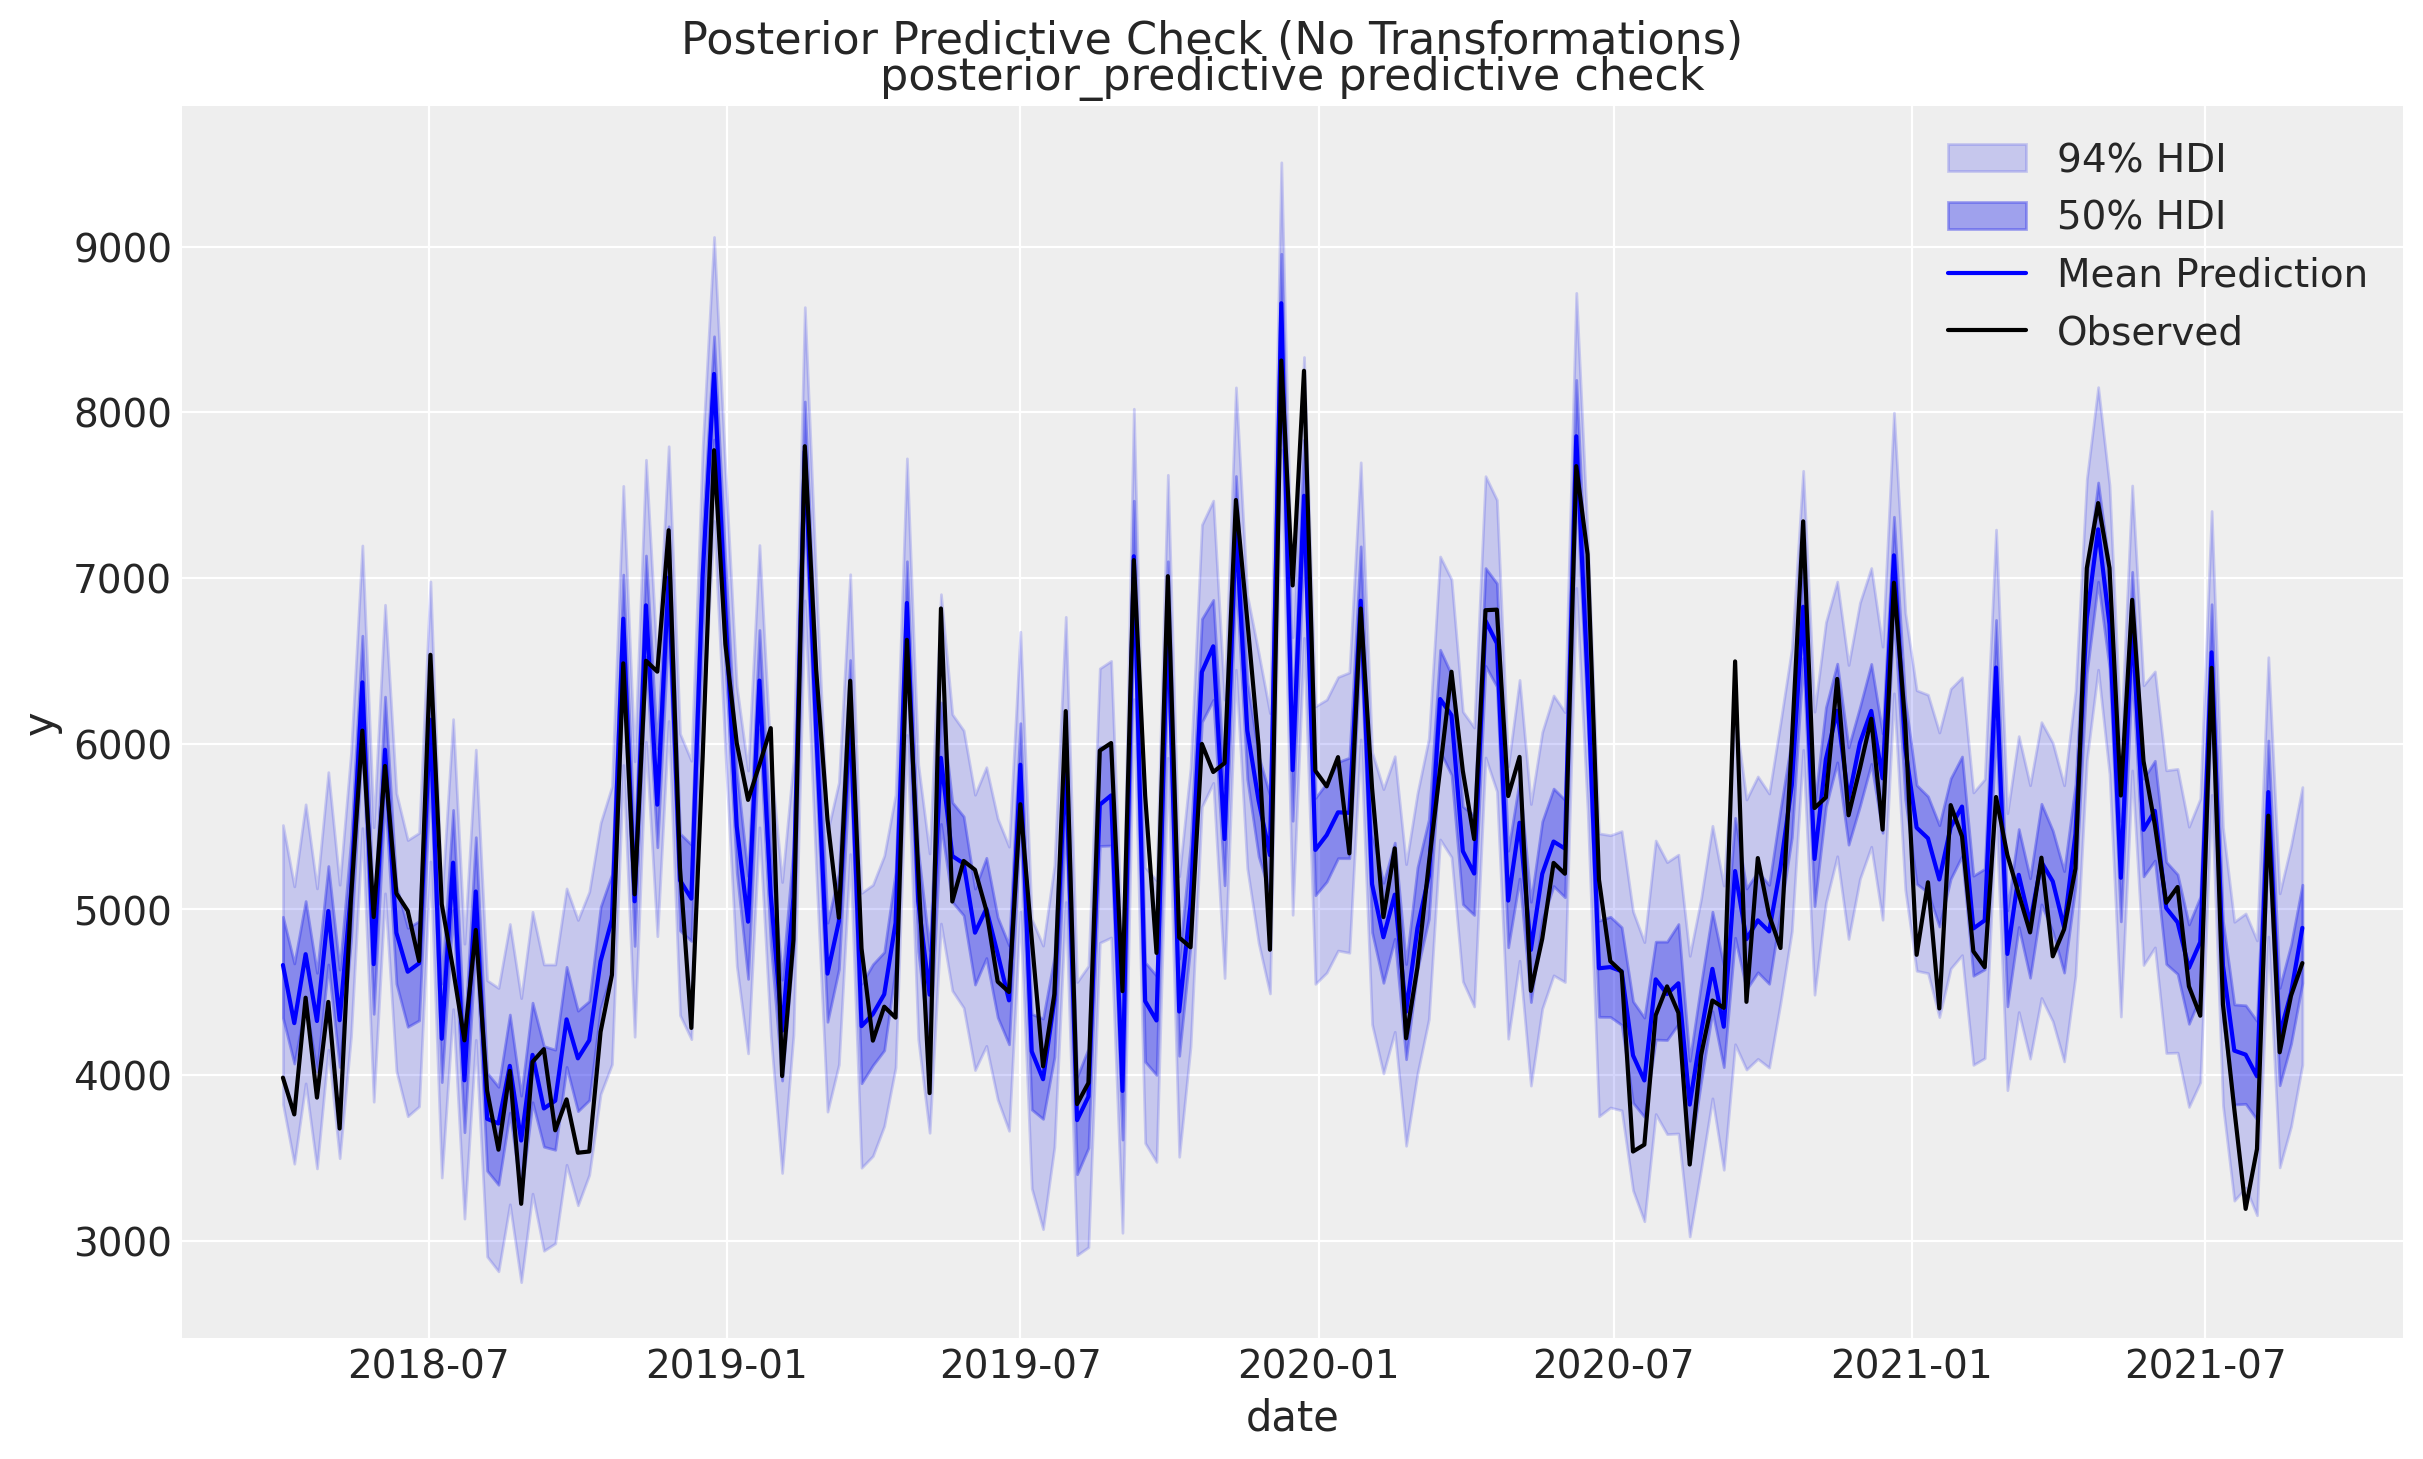

In [15]:
# Sample from posterior predictive distribution
mmm.sample_posterior_predictive(X, extend_idata=True, combined=True)

# Plot model fit
fig = mmm.plot_posterior_predictive(original_scale=True)
plt.suptitle("Posterior Predictive Check (No Transformations)", fontsize=16, y=1.02);

## Contribution Analysis

Now let's understand how much each component contributes to sales!

### Component Contributions Over Time

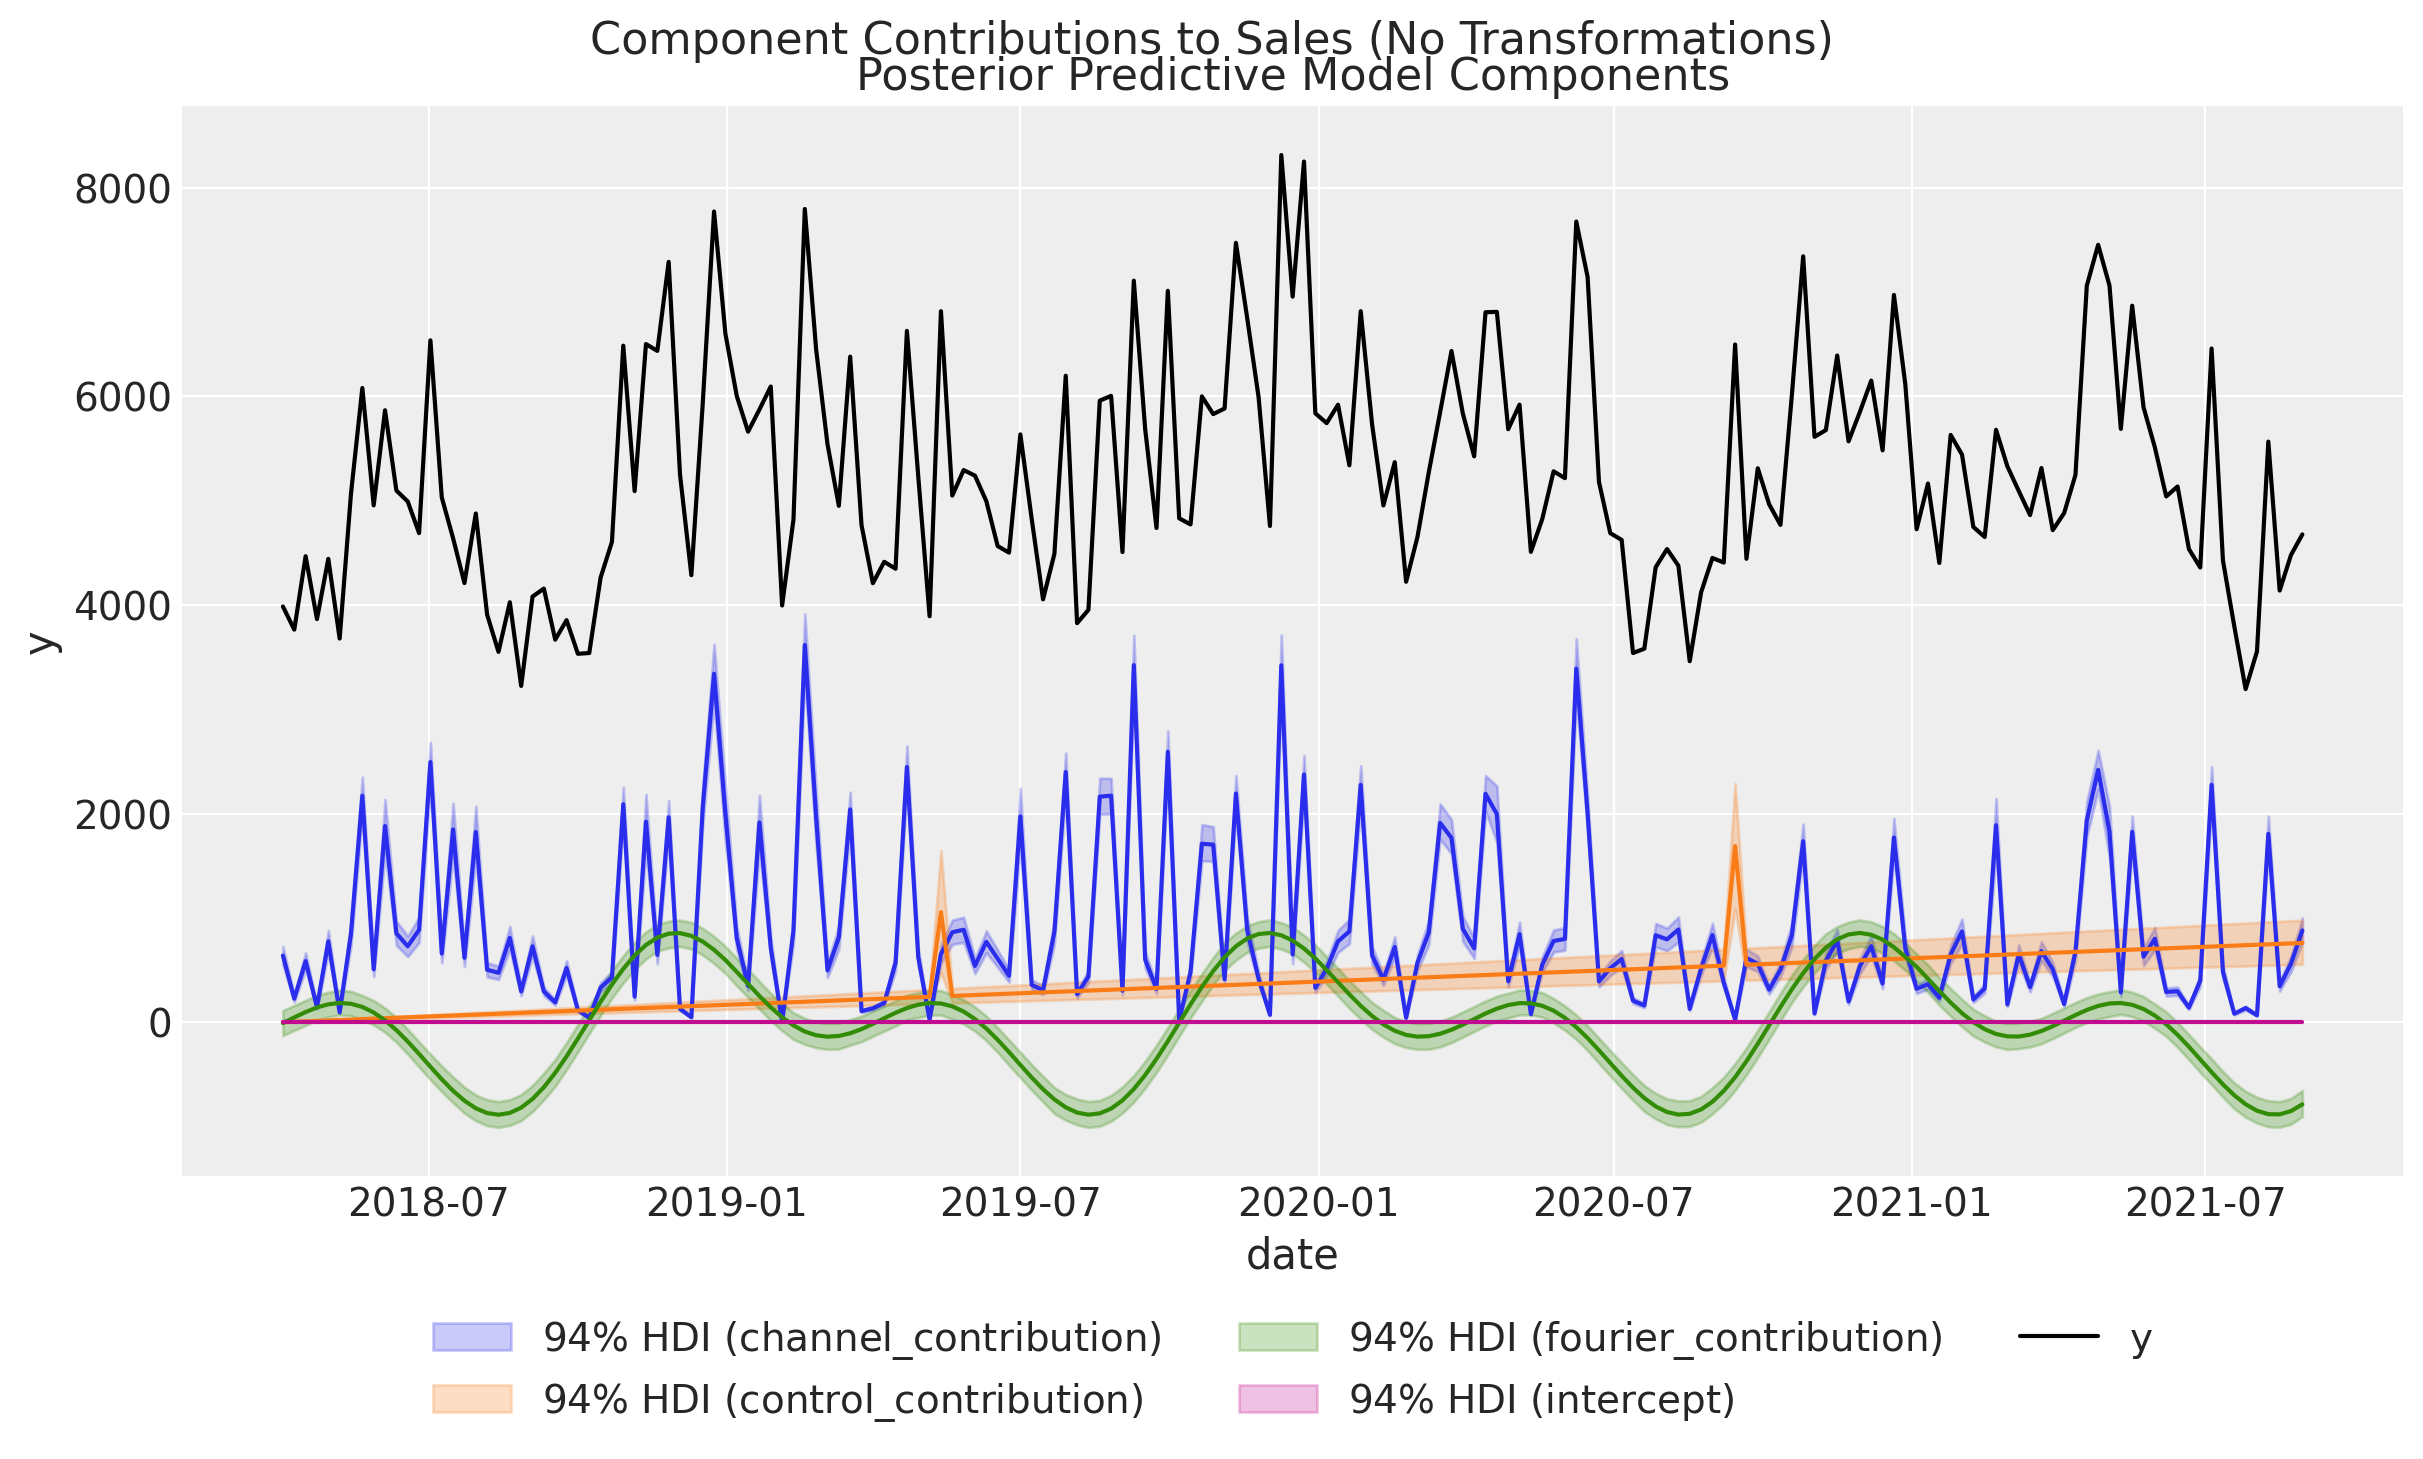

In [16]:
fig = mmm.plot_components_contributions(original_scale=True)
plt.suptitle("Component Contributions to Sales (No Transformations)", fontsize=16, y=1.02);

### Waterfall Chart: Total Contribution by Component

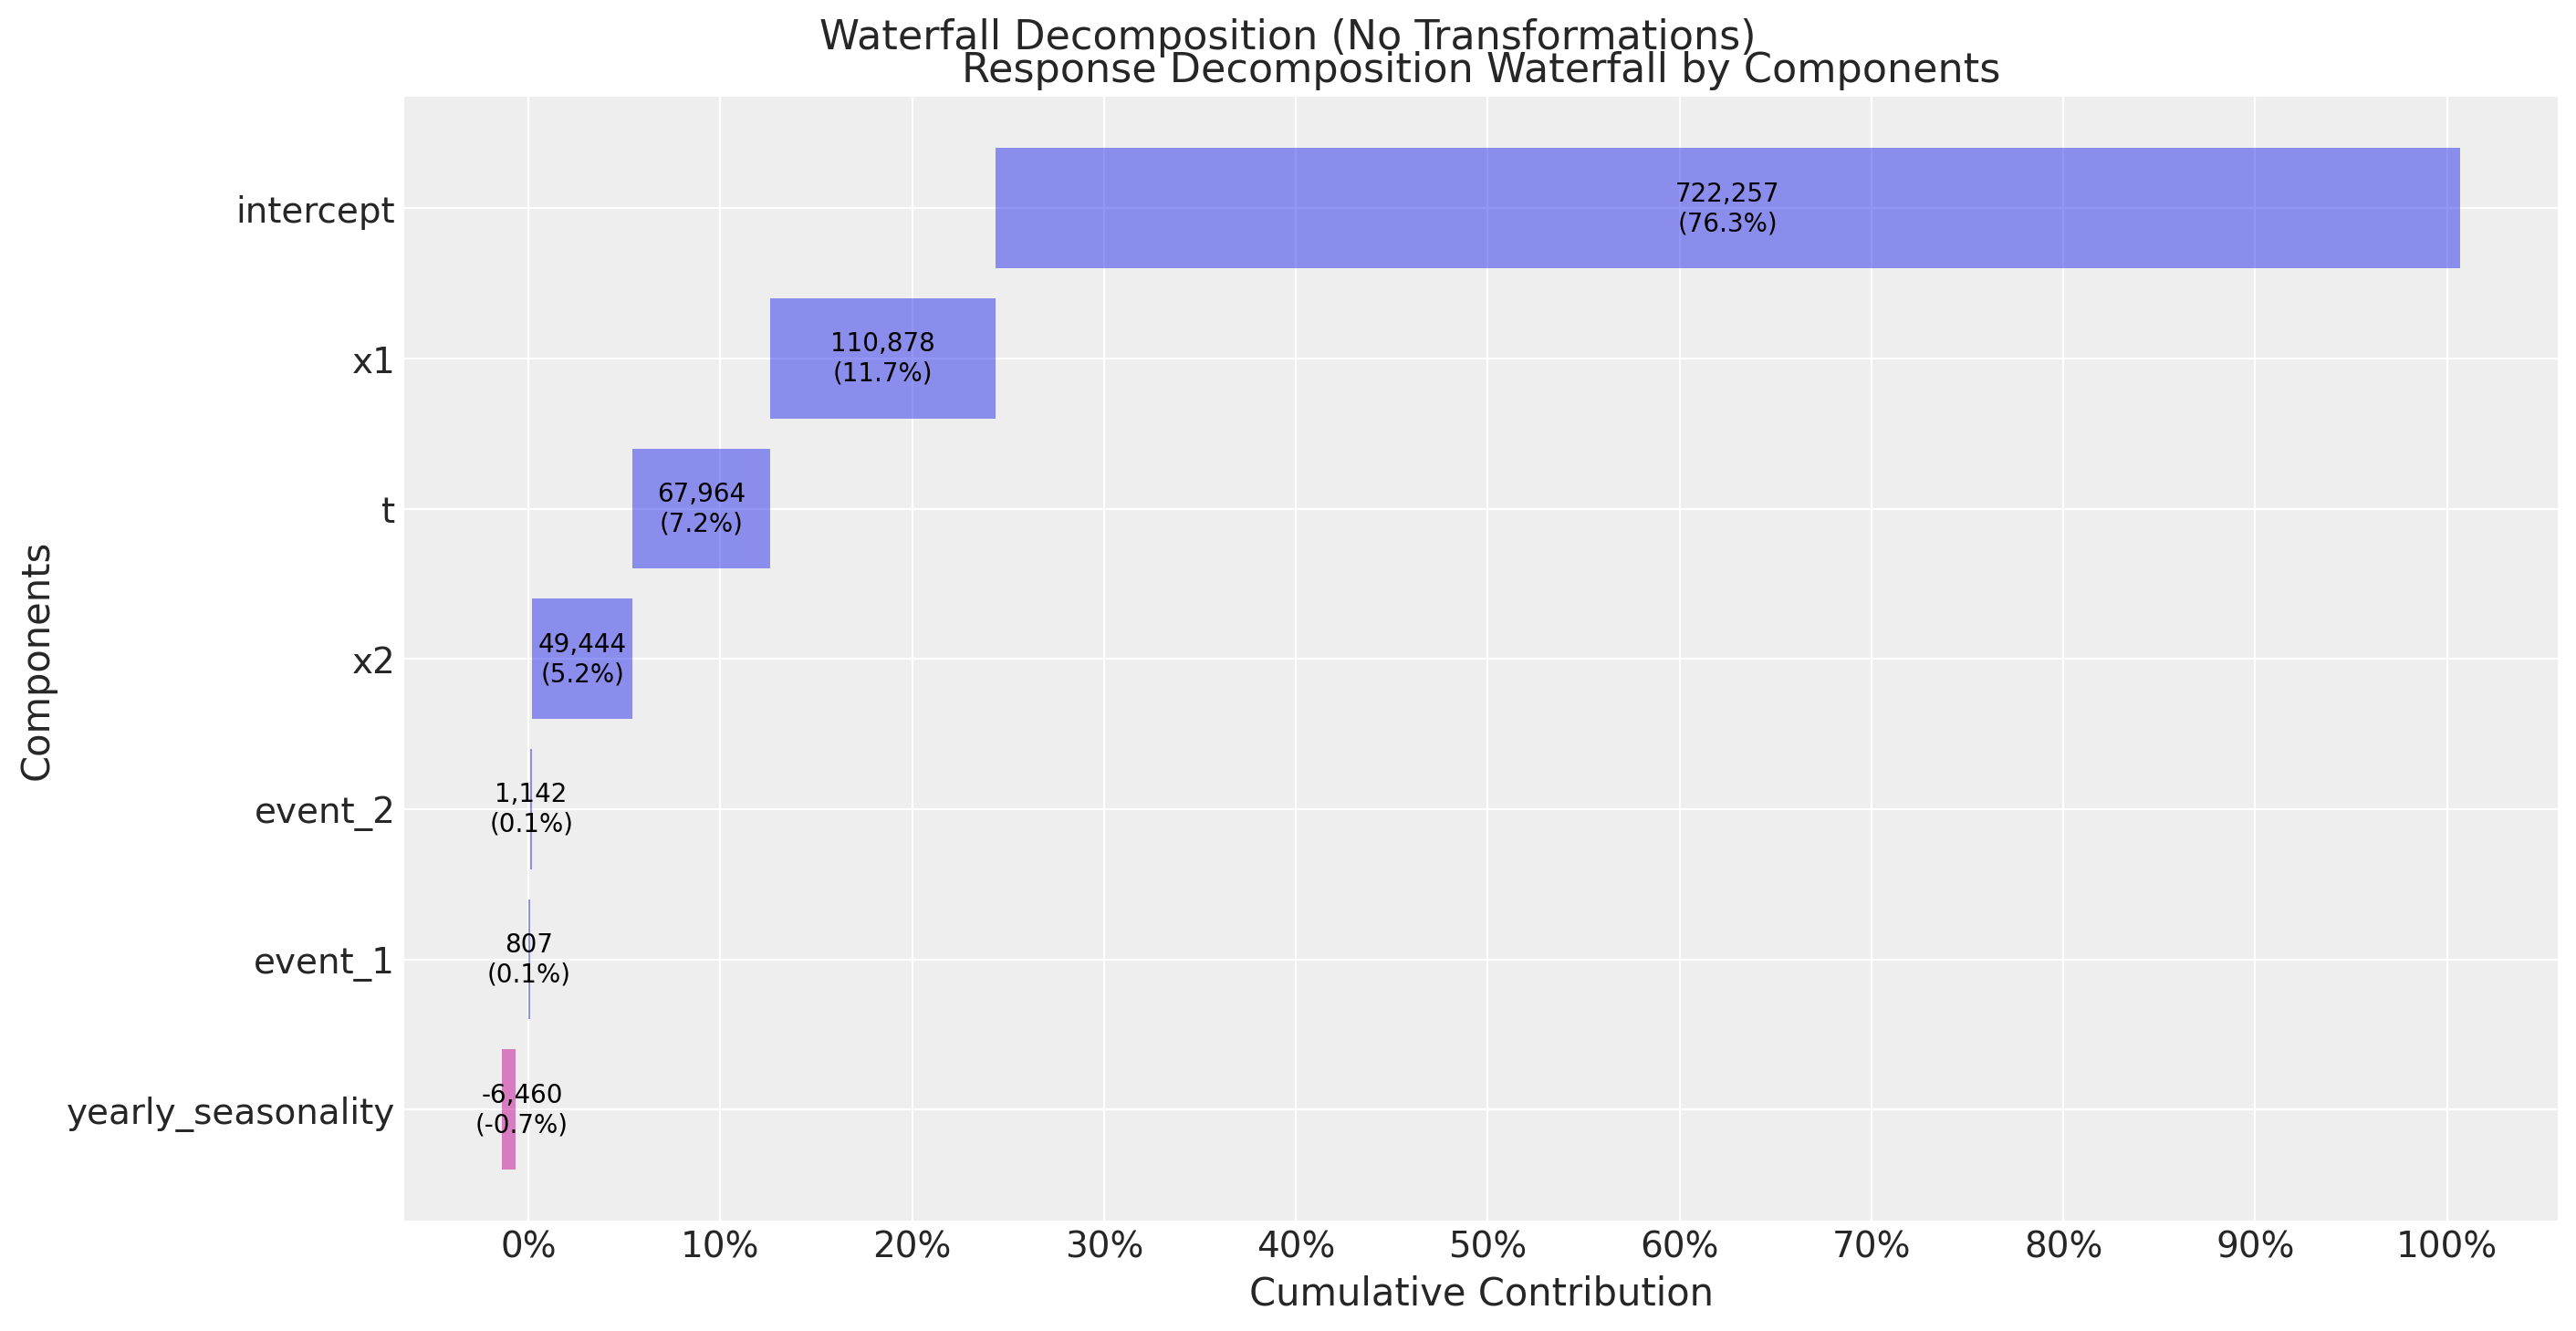

In [17]:
# Waterfall decomposition
fig = mmm.plot_waterfall_components_decomposition()
plt.suptitle("Waterfall Decomposition (No Transformations)", fontsize=16, y=1.02);

### Channel Contribution Share

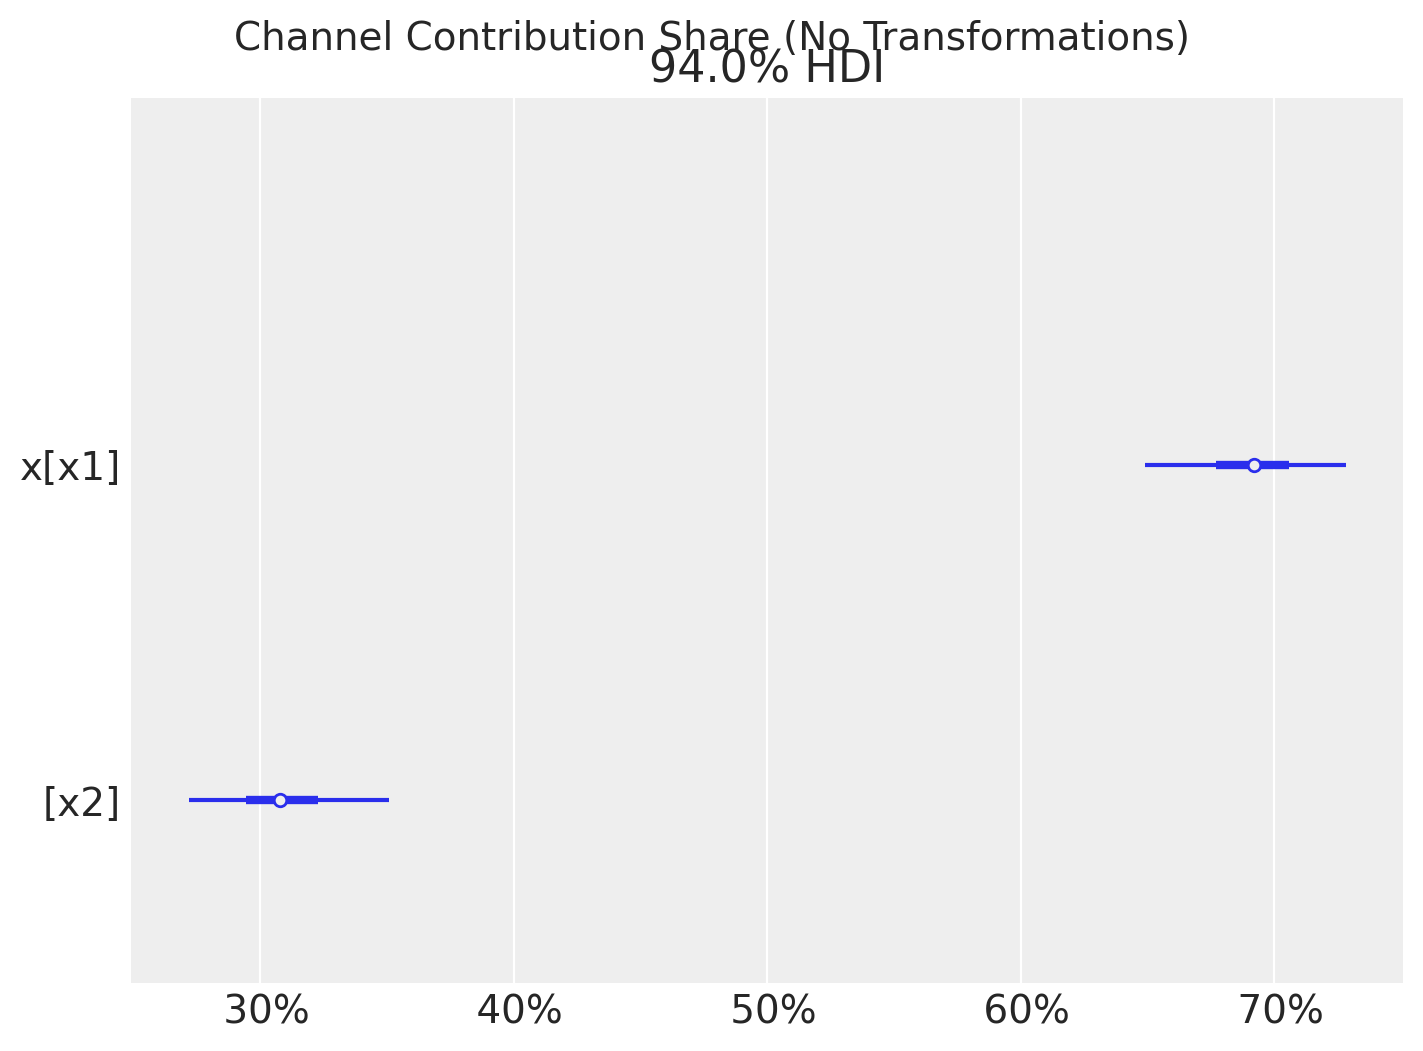

In [18]:
# Plot channel contribution share
fig = mmm.plot_channel_contribution_share_hdi(figsize=(7, 5))
plt.suptitle("Channel Contribution Share (No Transformations)", fontsize=14, y=1.02);

## Comparison: With vs Without Transformations

**Key Differences:**

1. **Model Parameters:**
   - **With transformations**: `adstock_alpha` (GeometricAdstock), `saturation_lam` + `saturation_beta` (LogisticSaturation)
   - **Without transformations**: Only `saturation_beta` (NoSaturation - linear coefficients), no adstock parameters

2. **Assumptions:**
   - **With transformations**: Media effects carry over time (adstock) and have diminishing returns (saturation)
   - **Without transformations**: Immediate impact (NoAdstock), linear relationship (NoSaturation)

3. **Use Cases:**
   - **With transformations**: More realistic for most marketing scenarios where ads have lagged effects and diminishing returns
   - **Without transformations**: Simpler model, useful for baseline comparison or when transformations don't apply

4. **Model Complexity:**
   - **With transformations**: More parameters to estimate (alpha, lam, beta), potentially better fit but more complex
   - **Without transformations**: Fewer parameters (only beta), faster fitting, easier interpretation

5. **Implementation:**
   - **With transformations**: `adstock=GeometricAdstock(l_max=8)`, `saturation=LogisticSaturation()`
   - **Without transformations**: `adstock=NoAdstock()`, `saturation=NoSaturation()` (no parameters needed!)

## Summary

This notebook demonstrated how to build an MMM model **without adstock or saturation transformations**. This simpler model:

- Assumes immediate media impact (no carry-over)
- Assumes linear relationships (no diminishing returns)
- Has fewer parameters to estimate
- Can serve as a baseline for comparison with more complex models

For most real-world marketing applications, models **with transformations** are more appropriate, but this simplified version can be useful for:
- Understanding the baseline model structure
- Comparing model performance
- Scenarios where transformations are not applicable